In [2]:
!pip install joblib

In [3]:
from joblib import Parallel, delayed

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [4]:
!pip install -q cython numpy
!pip install -q git+https://github.com/pranaysy/ETCPy.git

In [5]:
!pip install -q pandas numpy tqdm matplotlib seaborn

In [6]:
import ETC
from ETC import CCC

import numpy as np
import pandas as pd
import os
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

print("ETCPy installed successfully!")

ETCPy installed successfully!


In [7]:
BASE_PATH = r"D:\capstone"

ASD_PATH = os.path.join(BASE_PATH, "data/cc200_ASD2")
SAVE_PATH = os.path.join(BASE_PATH, "results/v1/ccc_outputs/set2")

print("ASD:", len(os.listdir(ASD_PATH)))

ASD: 255


In [8]:
def load_subject(path):
    data = np.loadtxt(path)

    return data

## compute ccc directly by passing the num_of_bins as parameter for discretization

In [9]:
def compute_ccc_matrix(data, L=50, w=10, k=5, bins=8):
    n_rois = data.shape[1]
    C = np.zeros((n_rois, n_rois))

    for i in range(n_rois):
        for j in range(n_rois):
            if i != j:
                try:
                    C[i, j] = CCC.compute(
                        seq_x=list(data[:, i]),  # pass raw float data
                        seq_y=list(data[:, j]),  # pass raw float data
                        LEN_past=L,
                        ADD_meas=w,
                        STEP_size=k,
                        n_partitions=bins  # ← ETCPy discretizes internally
                    )
                except Exception as e:
                    C[i, j] = 0

    np.fill_diagonal(C, 0)
    return C

In [10]:
def analyze_and_save(C, name, save_dir):
    os.makedirs(save_dir, exist_ok=True)

    # remove diagonal
    mask = ~np.eye(C.shape[0], dtype=bool)
    vals = C[mask]

    stats = {
        "file": name,
        "mean": float(np.mean(vals)),
        "std": float(np.std(vals)),
        "min": float(np.min(vals)),
        "max": float(np.max(vals)),
        "positive": int(np.sum(vals > 0)),
        "negative": int(np.sum(vals < 0)),
        "zero": int(np.sum(vals == 0)),
        "symmetric": bool(np.allclose(C, C.T)),
        "asymmetry": float(np.mean(np.abs(C - C.T)))
    }

    # save stats
    import json
    with open(f"{save_dir}/{name}_stats.json", "w") as f:
        json.dump(stats, f, indent=4)

    # heatmap
    plt.figure(figsize=(6,5))
    sns.heatmap(C, cmap="coolwarm", center=0)
    plt.title(f"CCC Heatmap - {name}")
    plt.savefig(f"{save_dir}/{name}_heatmap.png", dpi=300)
    plt.close()

    # distribution
    plt.figure(figsize=(5,4))
    plt.hist(vals, bins=50)
    plt.title(f"CCC Distribution - {name}")
    plt.savefig(f"{save_dir}/{name}_dist.png", dpi=300)
    plt.close()

    return stats

# JOBLIB PARALLELIZATION

In [11]:
from tqdm import tqdm
from contextlib import contextmanager
import joblib

@contextmanager
def tqdm_joblib(tqdm_object):
    class TqdmBatchCompletionCallback(joblib.parallel.BatchCompletionCallBack):
        def __call__(self, *args, **kwargs):
            tqdm_object.update(n=self.batch_size)
            return super().__call__(*args, **kwargs)

    old_callback = joblib.parallel.BatchCompletionCallBack
    joblib.parallel.BatchCompletionCallBack = TqdmBatchCompletionCallback

    try:
        yield tqdm_object
    finally:
        joblib.parallel.BatchCompletionCallBack = old_callback
        tqdm_object.close()

In [12]:
def process_subject(file_path, save_dir):
    try:
        name = os.path.splitext(os.path.basename(file_path))[0]

        print(f"Processing {name}")

        data = load_subject(file_path)
        C = compute_ccc_matrix(data)

        # save matrices
        np.save(f"{save_dir}/{name}.npy", C)
        np.savetxt(f"{save_dir}/{name}.csv", C, delimiter=",")

        stats = analyze_and_save(C, name, save_dir)

        return stats

    except Exception as e:
        print(f"Error: {file_path} -> {e}")
        return None

In [14]:
#N = 50 #Number of subjects you want to process

#asd_files = sorted(os.listdir(ASD_PATH))[0:N]
asd_files = sorted(os.listdir(ASD_PATH))[100:120]
asd_files = [os.path.join(ASD_PATH, f) for f in asd_files]

SAVE_ASD = os.path.join(SAVE_PATH, "ASD")
os.makedirs(SAVE_ASD, exist_ok=True)

with tqdm_joblib(tqdm(total=len(asd_files))) as progress_bar:
  results = Parallel(n_jobs=2)(
      delayed(process_subject)(f, SAVE_ASD) for f in asd_files
  )

# save summary
df = pd.DataFrame([r for r in results if r is not None])
df.to_csv(f"{SAVE_ASD}/summary.csv", index=False)

df.head()

100%|██████████| 20/20 [14:16:27<00:00, 2569.39s/it]    


,file,mean,std,min,max,positive,negative,zero,symmetric,asymmetry
0,NYU_0050964_rois_cc200,-0.008599,0.008582,-0.041422,0.030555,6335,33463,2,False,0.008257
1,NYU_0050965_rois_cc200,-0.007920,0.009046,-0.041263,0.030958,7550,32249,1,False,0.008852
2,NYU_0050966_rois_cc200,-0.009266,0.008978,-0.041667,0.028566,6006,33792,2,False,0.008863
3,NYU_0050967_rois_cc200,-0.008408,0.009023,-0.040658,0.037372,6943,32856,1,False,0.008832
4,NYU_0050968_rois_cc200,-0.009340,0.008539,-0.040715,0.029286,5408,34391,1,False,0.008204


# THE END

Range: -2.982 to 4.283
Std: 1.4428


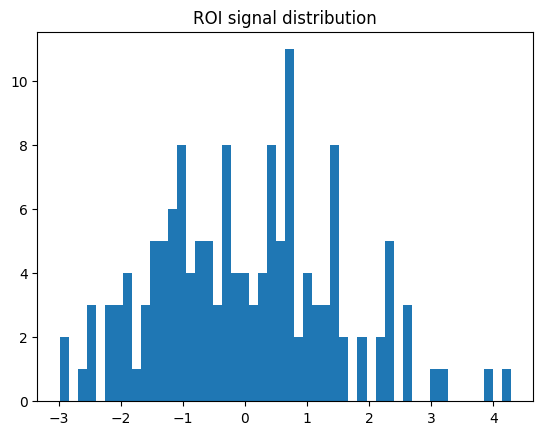

Bin counts: [ 0 10 24 34 29 32 10  5  1  1]


In [16]:
# Check one subject's signal distribution
data = load_subject(asd_files[0])
roi = data[:, 0]
print(f"Range: {roi.min():.3f} to {roi.max():.3f}")
print(f"Std: {roi.std():.4f}")
plt.hist(roi, bins=50)
plt.title("ROI signal distribution")
plt.show()

# See what equal-width bins actually look like
bins = np.linspace(roi.min(), roi.max(), 9)
digitized = np.digitize(roi, bins)
print("Bin counts:", np.bincount(digitized))

In [17]:
compute_ccc_matrix(data, L=20, w=5, k=3, bins=8)

array([[ 0.        , -0.02620881, -0.03150407, ..., -0.02824134,
        -0.02358793, -0.03145058],
       [-0.03835045,  0.        , -0.0389923 , ..., -0.03733419,
        -0.03658537, -0.0364249 ],
       [-0.02102054, -0.01433462,  0.        , ..., -0.01428113,
        -0.01444159, -0.0156718 ],
       ...,
       [-0.01583226, -0.01075096, -0.01845315, ...,  0.        ,
        -0.00818357, -0.02166239],
       [-0.02888318, -0.03075524, -0.03022037, ..., -0.01470903,
         0.        , -0.03043432],
       [-0.01599273, -0.02508558, -0.01882756, ..., -0.02369491,
        -0.01984382,  0.        ]], shape=(200, 200))

In [18]:
# Are negative values consistent across subjects or random noise?
# Load a few matrices and check agreement on sign
C1 = np.load(f"{SAVE_ASD}/Caltech_0051456_rois_cc200.npy")
C2 = np.load(f"{SAVE_ASD}/Caltech_0051457_rois_cc200.npy")

# What fraction of pairs agree on sign across subjects?
sign_agreement = np.mean(np.sign(C1) == np.sign(C2))
print(f"Sign agreement: {sign_agreement:.2%}")

Sign agreement: 66.72%


 check if positives are spatially structured:

In [19]:
# Where are the positive values clustering?
positive_mask = C1 > 0
print(f"Total positives: {positive_mask.sum()}")  # ~7500 from your summary

# Which ROIs have the most positive outgoing connections?
positive_per_roi = positive_mask.sum(axis=1)
top_rois = np.argsort(positive_per_roi)[-10:]
print("ROIs with most positive connections:", top_rois)

Total positives: 7530
ROIs with most positive connections: [ 82   9 106  70   6 103 191 172 115  31]


In [21]:
!pip install scikit-learn

  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.0 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.0 MB 223.9 kB/s eta 0:00:34
   -- -------------------

In [22]:
# Load raw and skip normalization
data_raw = np.loadtxt(asd_files[0])
# Compare one pair z-scored vs raw
from sklearn.preprocessing import scale
data_zscored = scale(data_raw)

ccc_raw = CCC.compute(list(data_raw[:,0]), list(data_raw[:,1]), LEN_past=50, ADD_meas=10, STEP_size=5, n_partitions=8)
ccc_z = CCC.compute(list(data_zscored[:,0]), list(data_zscored[:,1]), LEN_past=50, ADD_meas=10, STEP_size=5, n_partitions=8)

print(f"Raw: {ccc_raw:.4f}, Z-scored: {ccc_z:.4f}")

Raw: -0.0223, Z-scored: -0.0223
